# 실험 2: Classifier guidance (일반 DDPM)

## 0. 실행 설정 / 라이브러리

In [15]:
import os
import subprocess
import sys
import time
from pathlib import Path

RUN_SEEDS = list(range(10))
RESULTS_CSV = "exp2_classifier_guidance.csv"
CLASSIFIER_EPOCHS = 100
STEPS = 10
RESET_CSV = True
SCALE = 1.0
GPU_ID = None
if GPU_ID is None:
    out = subprocess.check_output(
        ["nvidia-smi", "--query-gpu=index,memory.used,utilization.gpu", "--format=csv,noheader,nounits"]).decode()
    rows = [tuple(int(v) for v in l.split(",")) for l in out.strip().splitlines()]
    GPU_ID = str(min(rows, key=lambda r: (r[1], r[2]))[0])
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID
print("사용 GPU:", GPU_ID)

사용 GPU: 0


In [16]:
HERE = Path.cwd().resolve()
ROOT = HERE.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.metrics import f1_score, confusion_matrix, precision_recall_fscore_support
from tqdm.auto import tqdm

from models import Unet, Classifier, NoisyClassifier
from utils import set_seed, DEVICE, EMA, metrics_to_rows, append_result_rows
from diffusion import GaussianDiffusion
from data import load_am, build_imbalanced_group_split, draw_from_pool, CLASS_NAMES, TRAIN_COUNTS, TEST_COUNTS, NUM_CLASSES, IMAGE_SIZE

## 1. 데이터 / 설정

In [17]:
image_size, channels, num_classes = IMAGE_SIZE, 3, NUM_CLASSES
batch_size = 40
data_root = os.environ.get("DATA_ROOT", "../../data/AM_image_data_3split")
timesteps = 1000
CKPT_DIR = ROOT / "diffusion_train" / "checkpoints"
UNET_DIM = 32
POOL_PER_CLASS = TRAIN_COUNTS[0] - TRAIN_COUNTS[1]
MINORITY = (1, 2)
GEN_BATCH = 60

all_x, all_y, all_groups = load_am(data_root)
test_x = test_y = test_x_dev = test_y_dev = None
print(f"클래스 {CLASS_NAMES} | 전체 이미지 {all_y.bincount().tolist()} | train {TRAIN_COUNTS}, test {TEST_COUNTS}")
ddpm = GaussianDiffusion(timesteps=timesteps, image_size=image_size, channels=channels)

train_x = train_y = None


def iterate_batches(n, bs):
    perm = torch.randperm(n, device=DEVICE)
    for i in range(0, n - bs + 1, bs):
        yield perm[i:i + bs]

클래스 ['Normal', 'Underfill_50FR', 'Underfill_Fan'] | 전체 이미지 [915, 591, 459] | train [800, 80, 80], test [100, 100, 100]


## 2. 함수 정의

In [18]:
def set_split(seed):
    global train_x, train_y, test_x, test_y, test_x_dev, test_y_dev
    tr, te = build_imbalanced_group_split(all_y, all_groups, TRAIN_COUNTS, TEST_COUNTS, seed)
    assert not set(tr.tolist()) & set(te.tolist()), "train/test에 같은 이미지가 있음"
    train_x, train_y = all_x[tr].to(DEVICE), all_y[tr].to(DEVICE)
    test_x, test_y = all_x[te], all_y[te]
    test_x_dev, test_y_dev = test_x.to(DEVICE), test_y.to(DEVICE)
    assert train_y.bincount(minlength=num_classes).tolist() == TRAIN_COUNTS
    assert test_y.bincount(minlength=num_classes).tolist() == TEST_COUNTS


CLASSIFIER_LR, CLASSIFIER_BETAS = 2e-4, (0.5, 0.9)


def train_eval_classifier(seed, pool, tag):
    set_seed(seed)
    clf = Classifier(num_classes=num_classes, img_channels=channels, image_size=image_size).to(DEVICE)
    opt = torch.optim.Adam(clf.parameters(), lr=CLASSIFIER_LR, betas=CLASSIFIER_BETAS)
    loss_fn = nn.CrossEntropyLoss()
    clf.train()
    total_steps = (len(train_x) // batch_size) * CLASSIFIER_EPOCHS
    step, losses, t0 = 0, [], time.time()
    for epoch in range(CLASSIFIER_EPOCHS):
        for idx in iterate_batches(len(train_x), batch_size):
            x, y = train_x[idx], train_y[idx]
            if pool is not None:
                xf, yf = draw_from_pool(pool, y, DEVICE)
                if xf is not None:
                    x, y = torch.cat([x, xf]), torch.cat([y, yf])
            loss = loss_fn(clf(x), y)
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item()); step += 1
            if step % max(1, total_steps // 5) == 0:
                print(f"[{tag} seed{seed}] step {step}/{total_steps} Cls={np.mean(losses[-50:]):.4f} elapsed={time.time()-t0:.1f}s")
    return clf


@torch.no_grad()
def evaluate_and_save(clf, seed, method, csv_path):
    clf.eval()
    pred = torch.cat([clf(test_x_dev[i:i + 500]).argmax(1) for i in range(0, len(test_y_dev), 500)]).cpu().numpy()
    y = test_y.numpy()
    cm = confusion_matrix(y, pred, labels=list(range(num_classes)))
    recall = cm.diagonal() / cm.sum(1)
    row = {"method": method, "seed": seed, "accuracy": (pred == y).mean(), "macro_f1": f1_score(y, pred, average="macro", zero_division=0),
           **{f"recall_{n}": r for n, r in zip(CLASS_NAMES, recall)}}
    print(f"[{method} seed{seed}] acc {row['accuracy']:.4f} | macro F1 {row['macro_f1']:.4f} | recall " + ", ".join(f"{n} {r:.3f}" for n, r in zip(CLASS_NAMES, recall)))
    print(cm)
    prec, rec, f1, sup = precision_recall_fscore_support(y, pred, labels=list(range(num_classes)), zero_division=0)
    append_result_rows(metrics_to_rows({"accuracy": row["accuracy"], "precision": prec, "recall": rec, "f1": f1, "support": sup}, seed, method), csv_path)
    cpath = Path(csv_path).with_name("confusion.csv")
    pd.DataFrame([{"method": method, "seed": seed, **{f"cm_{i}{j}": int(cm[i, j]) for i in range(num_classes) for j in range(num_classes)}}]).to_csv(
        cpath, mode="a", header=not cpath.exists(), index=False)


def load_unet(mode, seed):
    path = CKPT_DIR / f"{mode}_ema_seed{seed}.pt"
    if not path.exists():
        return None
    model = Unet(dim=UNET_DIM, channels=channels, num_classes=num_classes).to(DEVICE)
    model.load_state_dict(torch.load(path, map_location=DEVICE))
    model.eval()
    return model


NOISY_CLF_EPOCHS = 100
NOISY_CLF_LR, NOISY_CLF_BETAS = CLASSIFIER_LR, CLASSIFIER_BETAS


def train_noisy_classifier(seed):
    clf = NoisyClassifier(num_classes=num_classes, img_channels=channels).to(DEVICE)
    set_seed(seed)
    opt = torch.optim.Adam(clf.parameters(), lr=NOISY_CLF_LR, betas=NOISY_CLF_BETAS)
    loss_fn = nn.CrossEntropyLoss()
    clf.train()
    total = (len(train_x) // batch_size) * NOISY_CLF_EPOCHS
    step, losses, t0 = 0, [], time.time()
    for epoch in range(NOISY_CLF_EPOCHS):
        for idx in iterate_batches(len(train_x), batch_size):
            x, y = train_x[idx], train_y[idx]
            t = torch.randint(0, timesteps, (x.size(0),), device=DEVICE)
            loss = loss_fn(clf(ddpm.q_sample(x, t), t), y)
            opt.zero_grad(); loss.backward(); opt.step()
            losses.append(loss.item()); step += 1
            if step % max(1, total // 5) == 0:
                print(f"[NoisyClf seed{seed}] step {step}/{total} CE={np.mean(losses[-100:]):.4f} elapsed={time.time()-t0:.1f}s")
    clf.eval()
    return clf


@torch.no_grad()
def noisy_clf_report(clf, seed):
    res = {}
    for t_val in (50, 250, 500, 750, 950):
        pred = []
        for i in range(0, len(test_y_dev), 500):
            x = test_x_dev[i:i + 500]
            t = torch.full((x.size(0),), t_val, device=DEVICE, dtype=torch.long)
            pred.append(clf(ddpm.q_sample(x, t), t).argmax(1))
        res[t_val] = (torch.cat(pred) == test_y_dev).float().mean().item()
    print(f"[NoisyClf seed{seed}] test 정확도(노이즈 t별): " + ", ".join(f"t={k}: {v:.2f}" for k, v in res.items()))


@torch.no_grad()
def pool_report(clf, pool, method, seed):
    msg = []
    for c, x in pool.items():
        t = torch.zeros(x.size(0), device=DEVICE, dtype=torch.long)
        msg.append(f"{CLASS_NAMES[c]} {(clf(x, t).argmax(1) == c).float().mean().item():.1%}")
    print(f"[{method} seed{seed}] fake를 의도한 클래스로 판정한 비율 - " + ", ".join(msg))

## 실험 2: Classifier guidance (일반 DDPM) & 평가

In [19]:
def build_pool(model, noisy_clf, steps):
    pool = {}
    for c in MINORITY:
        xs = []
        for i in range(0, POOL_PER_CLASS, GEN_BATCH):
            y = torch.full((min(GEN_BATCH, POOL_PER_CLASS - i),), c, dtype=torch.long, device=DEVICE)
            xs.append(ddpm.sample_ddpm_respaced_cg(model, noisy_clf, y, DEVICE, steps=steps, scale=SCALE))
        pool[c] = torch.cat(xs)
    return pool

if RESET_CSV and not globals().get("_CSV_RESET_DONE"):
    for _f in (RESULTS_CSV, "confusion.csv"):
        Path(_f).unlink(missing_ok=True)
    _CSV_RESET_DONE = True

done = set()
if os.path.exists(RESULTS_CSV):
    _prev = pd.read_csv(RESULTS_CSV)
    done = set(zip(_prev["method"], _prev["seed"]))

for seed in RUN_SEEDS:
    method = f"2_classifier_guidance_ddpm_step{STEPS}_s{SCALE:g}"
    if (method, seed) in done:
        print(f"[{method} seed{seed}] 결과 있음 → 건너뜀"); continue
    set_split(seed)
    model = load_unet("ddpm", seed)
    if model is None:
        print(f"[seed{seed}] ddpm 체크포인트 없음 → 건너뜀 (diffusion_train 먼저 실행)"); continue
    print(f"\n===== {method} | Seed {seed} =====")
    t0 = time.time()
    noisy_clf = train_noisy_classifier(seed)
    noisy_clf_report(noisy_clf, seed)
    set_seed(seed)
    pool = build_pool(model, noisy_clf, STEPS)
    print(f"[{method} seed{seed}] fake 풀 생성 {time.time()-t0:.1f}초")
    pool_report(noisy_clf, pool, method, seed)
    clf = train_eval_classifier(seed, pool, tag="2")
    evaluate_and_save(clf, seed, method, RESULTS_CSV)
    print(f"[{method} seed{seed}] 총 {time.time()-t0:.1f}초")
    del pool


===== 2_classifier_guidance_ddpm_step10_s1 | Seed 0 =====
[NoisyClf seed0] step 480/2400 CE=0.5293 elapsed=5.1s
[NoisyClf seed0] step 960/2400 CE=0.4930 elapsed=7.3s
[NoisyClf seed0] step 1440/2400 CE=0.4551 elapsed=9.4s
[NoisyClf seed0] step 1920/2400 CE=0.4417 elapsed=11.4s
[NoisyClf seed0] step 2400/2400 CE=0.4301 elapsed=13.5s
[NoisyClf seed0] test 정확도(노이즈 t별): t=50: 0.67, t=250: 0.61, t=500: 0.37, t=750: 0.33, t=950: 0.33
[2_classifier_guidance_ddpm_step10_s1 seed0] fake 풀 생성 27.6초
[2_classifier_guidance_ddpm_step10_s1 seed0] fake를 의도한 클래스로 판정한 비율 - Underfill_50FR 5.8%, Underfill_Fan 94.4%
[2 seed0] step 480/2400 Cls=0.4442 elapsed=2.9s
[2 seed0] step 960/2400 Cls=0.2918 elapsed=4.0s
[2 seed0] step 1440/2400 Cls=0.2120 elapsed=5.1s
[2 seed0] step 1920/2400 Cls=0.1595 elapsed=6.3s
[2 seed0] step 2400/2400 Cls=0.1375 elapsed=7.4s
[2_classifier_guidance_ddpm_step10_s1 seed0] acc 0.8433 | macro F1 0.8403 | recall Normal 0.940, Underfill_50FR 0.660, Underfill_Fan 0.930
[[94  5  1]
 [2

## 결과 요약 / 대응표본 t-test

In [20]:
from scipy import stats

ALL_CSVS = {
    "exp0 baseline": ROOT / "exp0_baseline" / "exp0_baseline.csv",
    "exp1 오버샘플링": ROOT / "exp1_oversampling" / "exp1_oversampling.csv",
    "exp2 guidance": ROOT / "exp2_classifier_guidance" / "exp2_classifier_guidance.csv",
}

runs, own = {}, set()
for name, path in ALL_CSVS.items():
    if Path(path).exists() and Path(path).stat().st_size > 0:
        df = pd.read_csv(path).drop_duplicates(["method", "seed", "class"], keep="last")
        df["class"] = df["class"].astype(str)
        for method, dm in df.groupby("method"):
            macro = dm[dm["class"] == "macro"].set_index("seed")
            wide = pd.DataFrame({"accuracy": macro["accuracy"], "macro_f1": macro["f1"]})
            for i, n in enumerate(CLASS_NAMES):
                wide[f"recall_{n}"] = dm[dm["class"] == str(i)].set_index("seed")["recall"]
            key = name if df["method"].nunique() == 1 else f"{name} [{method.split('step10_')[-1]}]"
            runs[key] = wide
            if Path(path).name == Path(RESULTS_CSV).name:
                own.add(key)

if not own:
    print("아직 결과가 없다")
else:
    seeds = sorted(set.intersection(*[set(runs[k].index) for k in own]))
    rows = []
    for name, g in runs.items():
        g = g.reindex(seeds).dropna(subset=["accuracy"])
        rows.append({"방법": name, "n": len(g), "Accuracy": f"{g.accuracy.mean():.4f}", "macro F1": f"{g.macro_f1.mean():.4f}",
                     **{f"recall {n}": f"{g[f'recall_{n}'].mean():.3f}" for n in CLASS_NAMES}})
    print(f"===== 성능 (이 노트북의 seed {seeds}) =====")
    display(pd.DataFrame(rows).set_index("방법"))

    rows = []
    for k in sorted(own):
        for name, ref in runs.items():
            if name in own:
                continue
            common = runs[k].index.intersection(ref.index)
            if len(common) < 2:
                continue
            for metric in ("accuracy", "macro_f1"):
                d = runs[k].loc[common, metric] - ref.loc[common, metric]
                t, p = stats.ttest_rel(runs[k].loc[common, metric], ref.loc[common, metric])
                rows.append({"이 노트북": k, "비교 대상": name, "지표": metric, "n": len(common), "평균 차이": round(d.mean(), 4), "p": round(p, 4), "우세 seed": f"{(d > 0).sum()}/{len(d)}"})
    print("\n===== 대응표본 t-test (이 노트북 − 비교 대상) =====")
    display(pd.DataFrame(rows).set_index(["이 노트북", "비교 대상", "지표"]) if rows else pd.DataFrame())

===== 성능 (이 노트북의 seed [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]) =====


,n,Accuracy,macro F1,recall Normal,recall Underfill_50FR,recall Underfill_Fan
방법,,,,,,
exp0 baseline,10,0.8413,0.8362,0.988,0.611,0.925
exp1 오버샘플링,10,0.7873,0.7755,0.925,0.533,0.904
exp2 guidance,10,0.8060,0.7966,0.947,0.556,0.915



===== 대응표본 t-test (이 노트북 − 비교 대상) =====


n   평균 차이       p 우세 seed
이 노트북         비교 대상         지표                                  
exp2 guidance exp0 baseline accuracy  10 -0.0353  0.1682    4/10
                            macro_f1  10 -0.0395  0.1798    4/10
              exp1 오버샘플링    accuracy  10  0.0187  0.0725    7/10
                            macro_f1  10  0.0211  0.0886    7/10

## 생성 샘플 보기

[NoisyClf seed0] step 480/2400 CE=0.5160 elapsed=1.7s
[NoisyClf seed0] step 960/2400 CE=0.4708 elapsed=3.4s
[NoisyClf seed0] step 1440/2400 CE=0.4521 elapsed=5.1s
[NoisyClf seed0] step 1920/2400 CE=0.4411 elapsed=6.7s
[NoisyClf seed0] step 2400/2400 CE=0.4267 elapsed=8.5s


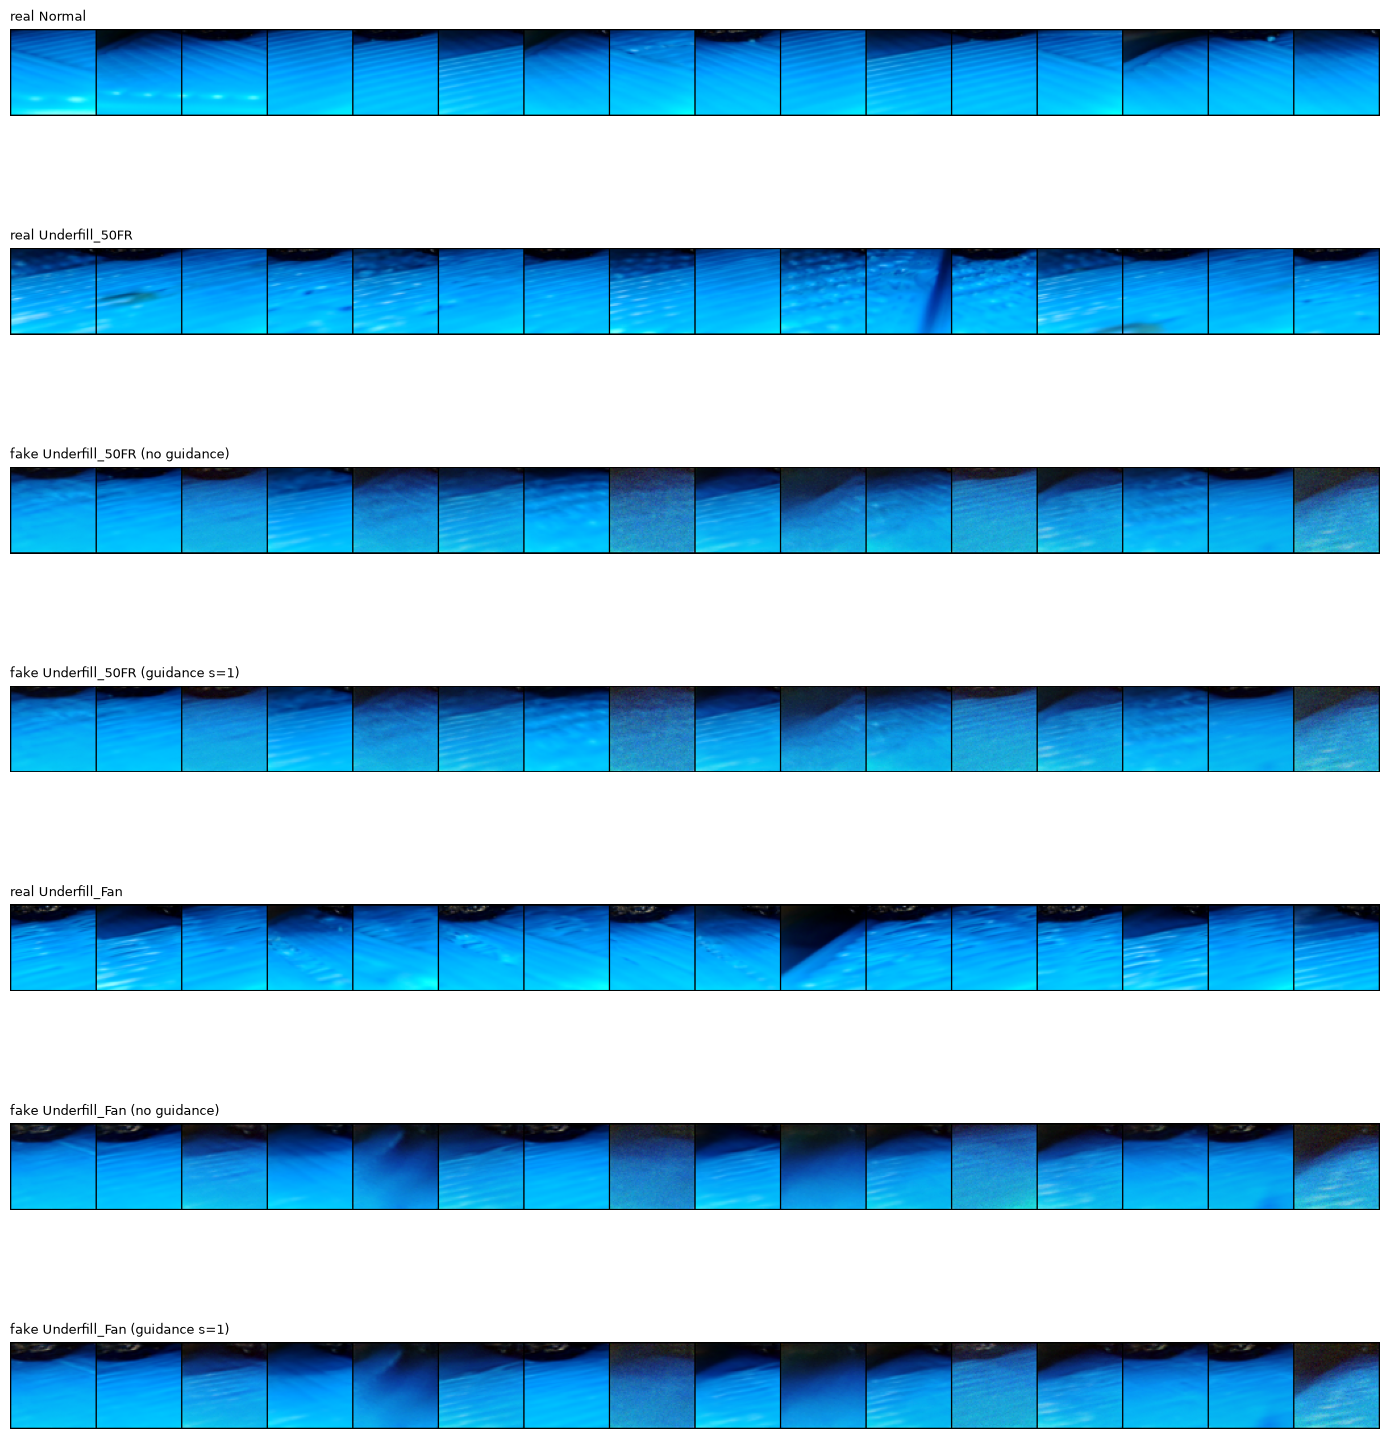

fake Underfill_50FR (no guidance): 노이즈 분류기가 Underfill_50FR로 판정한 비율 6.2%
fake Underfill_50FR (guidance s=1): 노이즈 분류기가 Underfill_50FR로 판정한 비율 6.2%
fake Underfill_Fan (no guidance): 노이즈 분류기가 Underfill_Fan로 판정한 비율 93.8%
fake Underfill_Fan (guidance s=1): 노이즈 분류기가 Underfill_Fan로 판정한 비율 100.0%


In [21]:
import matplotlib.pyplot as plt
from torchvision.utils import make_grid

SAMPLE_SEED = 0
N_SHOW = 16
set_split(SAMPLE_SEED)
model = load_unet("ddpm", SAMPLE_SEED)
assert model is not None, "ddpm 체크포인트가 없다 (diffusion_train 먼저 실행)"
noisy_clf = train_noisy_classifier(SAMPLE_SEED)

rows = [("real " + CLASS_NAMES[0], train_x[train_y == 0][:N_SHOW])]
for c in MINORITY:
    y = torch.full((N_SHOW,), c, dtype=torch.long, device=DEVICE)
    set_seed(SAMPLE_SEED)
    fake_plain = ddpm.sample_ddpm_respaced(model, y, DEVICE, steps=STEPS)
    set_seed(SAMPLE_SEED)
    fake_guided = ddpm.sample_ddpm_respaced_cg(model, noisy_clf, y, DEVICE, steps=STEPS, scale=SCALE)
    rows += [("real " + CLASS_NAMES[c], train_x[train_y == c][:N_SHOW]),
             (f"fake {CLASS_NAMES[c]} (no guidance)", fake_plain),
             (f"fake {CLASS_NAMES[c]} (guidance s={SCALE:g})", fake_guided)]
fig, axes = plt.subplots(len(rows), 1, figsize=(14, 2.3 * len(rows)))
for ax, (name, x) in zip(axes, rows):
    ax.imshow(make_grid(((x.detach().cpu() + 1) / 2).clamp(0, 1), nrow=N_SHOW, padding=1).permute(1, 2, 0)); ax.axis("off")
    ax.set_title(name, fontsize=9, loc="left")
plt.tight_layout(); plt.show()

with torch.no_grad():
    t0 = torch.zeros(N_SHOW, device=DEVICE, dtype=torch.long)
    for i, c in enumerate(MINORITY):
        for name, x in rows[2 + 3 * i: 4 + 3 * i]:
            print(f"{name}: 노이즈 분류기가 {CLASS_NAMES[c]}로 판정한 비율 {(noisy_clf(x, t0).argmax(1) == c).float().mean().item():.1%}")